# Online adaptation: how few pixels, and how fast after a change?

**Questions.** (1) If the server learns continuously, with no stored frames and no retraining step, how many pixels does the tag actually have to read? (2) When the room changes, how long does the loop take to readapt, and what does that cost?

**The loop** is the one from `adaptive_loop.ipynb`: bootstrap on full frames labelled by a teacher, send the tag a 96-bit code (one EPC), keep checking against occasional full frames. What changes here is the learner (`semwisp.server.OnlineLearner`):
* It keeps only running statistics, exponentially weighted with a half-life of 200 labelled frames: for each candidate region, its usual gray-level range when the room is empty, how often its bit is set in empty and in person frames, and which bits are set together. Each labelled frame is a constant-time update, then the frame is discarded.
* A new code is read off those statistics: regions are picked one at a time, each adding the most class separation given those already picked.
* If empty frames suddenly stop matching the learned background (more than 30% of all candidate bits set, three empty frames in a row), it throws its statistics away and goes back to full frames. This is the change detector.

The **batch** baseline stores the last 1,000 labelled frames and refits on them every 50 new ones, as in `adaptive_loop.ipynb`. It has no change detector.

**Pixels.** The tag is told which regions to look at; four candidate sets differ in how many pixels a 96-bit code can make it read:

| regions | what a bit looks at | pixels read |
|---|---|---|
| `cells` | a block of the 4×3, 8×6 or 16×12 grid, every pixel | up to 19,200 |
| `cells_s5` | the same blocks, one pixel per 5×5 patch | up to 768 |
| `cells_s10` | the same blocks, one pixel per 10×10 patch | up to 192 |
| `pixels` | one pixel (on a 4-pixel lattice) | 96 |

**Streams.** `piropo`: the five annotated sequences in recording order, every 2nd frame, twice. `switch`: the tag is "moved": PIROPO `training`, then a tile of the Mall dataset (a different scene), then PIROPO `training_seats` + `test2` (the first room with the furniture rearranged).

**Teachers.** *detector*: the COCO detector on the 160×120 frame (no labels used anywhere). *oracle*: the ground truth, to show what the loop does when its labels are right. The `switch` stream uses the oracle only, because no detector scores exist for the Mall tile.

**Findings in brief.**
1. **A learner with no stored frames and no refits keeps up with the batch baseline in one room.** On the first pass through PIROPO with true labels it reaches balanced accuracy 0.899 against 0.904 for the batch refit; with detector labels, 0.843 against 0.841.
2. **The tag needs very few pixels.** With true labels, a 96-bit code read from 96 single pixels (0.5% of the frame) scores 0.886, against 0.899 when the same code may use whole blocks (14,000 pixels). With detector labels the cost of going to 96 pixels is larger: 0.805 against 0.843.
3. **After the tag is moved, the online learner notices within about 30–50 queries and has a new code on the tag after about 300 queries and 270–290 full frames.** While it readapts it answers from full frames, so accuracy holds; the batch baseline, which does not notice, drops to about 72% correct after the move.
4. **But it does not become cheap again.** After readapting it still fetches a full frame on 30–50% of queries, against about 22–24% for the batch baseline, and after the return to the rearranged room its accuracy is lower (0.80–0.85 against 0.92). On this stream the batch refit is the better learner once it has caught up.
5. **Converging is where the online learner is weaker.** Shown the PIROPO stream a second time, the batch baseline falls to 3–5% full frames; the online learner stays at 8–32%.

So the two claims you want to make are supported in a first form: few pixels are enough, and readaptation time can be measured and is a few hundred queries. The open problem is the same as before, and is now the main one: the cost of checking. Everything on the `switch` stream uses true labels, single runs, and a second "room" that is a busy shopping-mall tile, so treat the readaptation numbers as a first measurement of the mechanism.


## 1. Results on PIROPO

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('..').resolve()))
from semwisp import piropo
from semwisp.frames import load_frames
from semwisp.metrics import readaptation, summary

INK, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID,
                     'text.color': INK, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
                     'axes.titlesize': 10, 'axes.titlelocation': 'left'})

R, rows = {}, []
for f in sorted((piropo.REPO / 'results' / 'online_adaptation').glob('*.npz')):
    with np.load(f) as z:
        m = json.loads(str(z['meta']))
        R[m['name']] = dict(df=pd.DataFrame({c: z[c] for c in z.files if c != 'meta' and not c.startswith('code_')}),
                            rects=z['code_rects'], meta=m)
        if m['stream'] == 'piropo':
            for p, s in m['by_pass'].items():
                rows.append(dict(teacher=m['teacher'], learner=m['learner'], regions=m['regions'],
                                 pixels_read=m['pixels_read'], **{'pass': int(p)}, balanced_acc=s['balanced_accuracy'],
                                 full_frame_rate=s['full_frame_rate'], up_bytes_per_query=s['up_bytes_per_query'],
                                 reconfigs=s['reconfigs']))
res = pd.DataFrame(rows).sort_values(['teacher', 'learner', 'pixels_read', 'pass'], ascending=[False, False, False, True])
res.style.format({'balanced_acc': '{:.3f}', 'full_frame_rate': '{:.1%}', 'up_bytes_per_query': '{:,.0f}',
                  'pixels_read': '{:,}'}).hide(axis='index')

teacher,learner,regions,pixels_read,pass,balanced_acc,full_frame_rate,up_bytes_per_query,reconfigs
oracle,online,cells,"14,000",1,0.899,28.1%,"5,407",16
oracle,online,cells,"14,000",2,0.917,12.8%,"2,479",8
oracle,online,cells_s5,660,1,0.891,25.9%,"4,990",14
oracle,online,cells_s5,660,2,0.931,16.3%,"3,132",11
oracle,online,cells_s10,153,1,0.895,34.7%,"6,680",20
oracle,online,cells_s10,153,2,0.929,20.4%,"3,926",14
oracle,online,pixels,96,1,0.886,34.6%,"6,657",20
oracle,online,pixels,96,2,0.935,7.9%,"1,521",5
oracle,batch,cells,"19,200",1,0.904,29.0%,"5,570",16
oracle,batch,cells,"19,200",2,0.954,4.5%,879,3


**Reading the table.** One row per configuration and pass; `pixels_read` is for the code in use at the end. All numbers include the bootstrap.

* **Online against batch, first pass.** Within 0.005 of each other on accuracy for both teachers when the online learner may use whole blocks.
* **Second pass.** With true labels the online learner improves to 0.92–0.94 but still fetches a full frame on 8–20% of queries (batch: 0.954 and 4.5%). With detector labels it barely settles at all (19–32%; batch 2.6%). Its statistics fade with a 200-frame half-life, so it keeps partly forgetting what it has seen; the batch window of 1,000 frames does not.
* **Bytes.** First-pass uplink is 5,000–8,600 bytes per query everywhere. As in `adaptive_loop.ipynb`, the full frames fetched for checking are the whole cost; the 12-byte replies are negligible.


## 2. Accuracy against pixels read

First pass only (everything new to the server). Each point is the online learner with one candidate set; the x position is the number of distinct pixels its final 96-bit code makes the tag read.

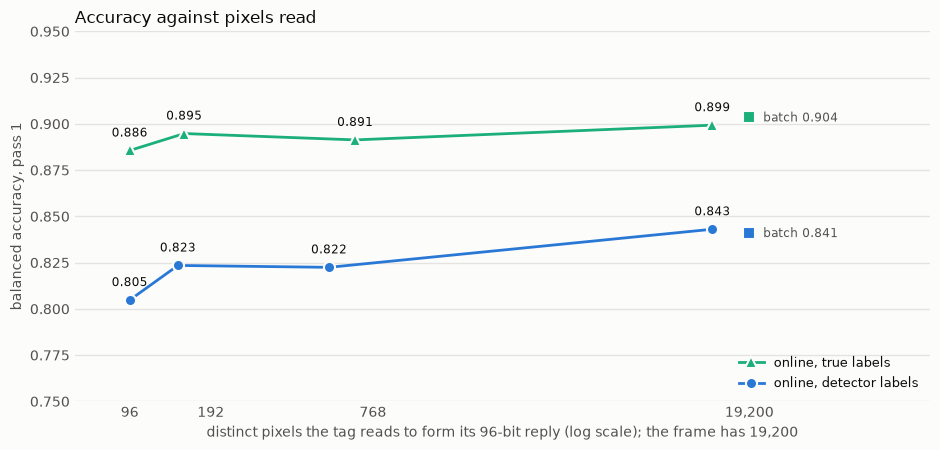

In [2]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
p1 = res[res['pass'] == 1]
for teacher, color, marker in [('oracle', AQUA, '^'), ('detector', BLUE, 'o')]:
    d = p1[(p1.teacher == teacher) & (p1.learner == 'online')].sort_values('pixels_read')
    ax.plot(d.pixels_read, d.balanced_acc, lw=2, marker=marker, ms=8, color=color, mec=SURFACE, mew=1.5,
            label=f'online, {"true labels" if teacher == "oracle" else "detector labels"}')
    for r in d.itertuples():
        ax.annotate(f'{r.balanced_acc:.3f}', (r.pixels_read, r.balanced_acc), (0, 10), textcoords='offset points',
                    ha='center', fontsize=8.5, color=INK)
    b = p1[(p1.teacher == teacher) & (p1.learner == 'batch')].iloc[0]
    ax.scatter([b.pixels_read], [b.balanced_acc], s=70, marker='s', color=color, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.annotate(f'batch {b.balanced_acc:.3f}', (b.pixels_read, b.balanced_acc), (10, -3), textcoords='offset points',
                ha='left', fontsize=8.5, color=MUTED)
ax.set_xscale('log'); ax.set_xlim(60, 90000); ax.set_ylim(0.75, 0.95)
ax.set_xticks([96, 192, 768, 19200], ['96', '192', '768', '19,200']); ax.minorticks_off()
ax.set_xlabel('distinct pixels the tag reads to form its 96-bit reply (log scale); the frame has 19,200')
ax.set_ylabel('balanced accuracy, pass 1')
ax.set_title('Accuracy against pixels read', fontsize=12)
ax.grid(axis='y', color=GRID, lw=1); ax.set_axisbelow(True); ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(frameon=False, loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()

**Reading the chart.** Going from whole blocks to one pixel per bit removes 99.5% of the pixels the tag has to read. With true labels (green) the line is nearly flat: 0.899, 0.891, 0.895, 0.886. With detector labels (blue) the same step costs about four points (0.843 to 0.805), most of it between 192 and 96 pixels. Single pixels are noisier than block means, and a noisy teacher on top of noisy bits compounds. The squares are the batch baseline, which is level with the online learner at the right-hand end.

What this does and does not show: the tag's *computation* drops to 96 comparisons, and the code needs 0.5% of the frame. It does not yet show an energy saving from *sensing*, because the simulated sensor still clocks out the whole frame; that needs a sensor mode that can skip pixels, or a measured cost for ignoring them.


## 3. Which pixels

The codes in use at the end of the PIROPO runs with true labels, drawn on a frame of the room. Left: the 96 single pixels. Right: the 96 regions of `cells_s10`, each read from the marked pixels only.

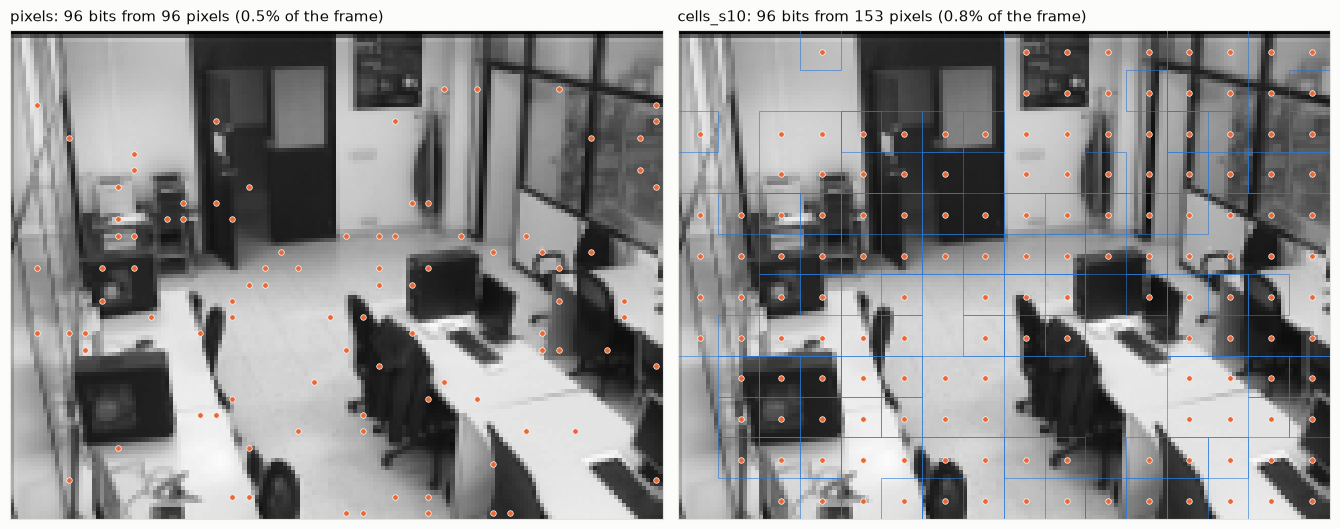

In [3]:
frame = load_frames(['training_seats'])['training_seats']['X'][1179]
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
for ax, name in zip(axes, ['piropo_oracle_online_pixels', 'piropo_oracle_online_cells_s10']):
    rects = R[name]['rects']
    used = np.zeros(frame.shape, bool)
    for x0, y0, w, h, s in rects:
        used[y0 + s // 2:y0 + h:s, x0 + s // 2:x0 + w:s] = True
        if w > 4:
            ax.add_patch(plt.Rectangle((x0 - .5, y0 - .5), w, h, fc='none', ec=BLUE, lw=0.7, alpha=0.6))
    ys, xs = np.nonzero(used)
    ax.imshow(frame, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    ax.scatter(xs, ys, s=16, color=ORANGE, edgecolor=SURFACE, linewidth=0.5)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{R[name]['meta']['regions']}: {len(rects)} bits from {used.sum()} pixels ({used.mean():.1%} of the frame)", fontsize=11)
plt.tight_layout(); plt.show()

**Which pixels.** The 96 single pixels are spread over the floor, the desks and the chairs, with few on the walls and ceiling: places a person passes through or occupies. They are chosen one at a time for what they add to those already chosen, which is why they do not cluster. The `cells_s10` code on the right reads 153 pixels on a regular 10-pixel lattice and combines them into regions of three sizes.

These are the codes at the end of the run, for the layout seen last. They are not fixed: every reconfiguration can move them.


## 4. Moving the tag: readaptation

The `switch` stream, split at the two changes. For each stretch:
* **detect**: queries until the server noticed the change and went back to full frames (0 at power-up; blank for the batch baseline, which has no detector).
* **deploy**: queries until the tag was running a code learned after the change, and the full frames fetched to get there.
* **after**: balanced accuracy and share of queries fetching a full frame from that point to the end of the stretch.

In [4]:
def room(seq):
    return seq.replace(' (test2)', '')

rows = []
for name, r in R.items():
    if r['meta']['stream'] != 'switch':
        continue
    d = r['df'].assign(room=r['df'].seq.map(room))
    for rm, g in d.groupby('room', sort=False):
        a = readaptation(g.reset_index(drop=True))
        rows.append(dict(learner=r['meta']['learner'], regions=r['meta']['regions'], room=rm, queries=len(g),
                         detect=a['detect_queries'], deploy=a['deploy_queries'], full_frames_to_deploy=a['full_frames_to_deploy'],
                         acc_after=a['after'] and a['after']['balanced_accuracy'],
                         full_frame_rate_after=a['after'] and a['after']['full_frame_rate'],
                         bytes_per_query_after=a['after'] and a['after']['up_bytes_per_query'],
                         acc_whole=a['whole']['balanced_accuracy']))
sw = pd.DataFrame(rows)
sw.style.format({'acc_after': '{:.3f}', 'acc_whole': '{:.3f}', 'full_frame_rate_after': '{:.1%}', 'bytes_per_query_after': '{:,.0f}',
                 'detect': '{:.0f}', 'deploy': '{:.0f}', 'full_frames_to_deploy': '{:.0f}'}, na_rep='').hide(axis='index')

learner,regions,room,queries,detect,deploy,full_frames_to_deploy,acc_after,full_frame_rate_after,bytes_per_query_after,acc_whole
batch,cells,room A (training),1987,0,200,200,0.929,20.0%,"3,848",0.936
batch,cells,room B (mall tile),2000,,114,57,0.927,24.4%,"4,695",0.914
batch,cells,"room A, rearranged",1110,,167,35,0.921,22.0%,"4,227",0.900
online,cells,room A (training),1987,0,200,200,0.892,15.3%,"2,956",0.902
online,cells,room B (mall tile),2000,31,290,272,0.916,49.3%,"9,476",0.926
online,cells,"room A, rearranged",1110,157,357,260,0.812,39.2%,"7,533",0.862
online,cells_s10,room A (training),1987,0,200,200,0.900,25.1%,"4,836",0.910
online,cells_s10,room B (mall tile),2000,31,290,274,0.906,47.0%,"9,026",0.917
online,cells_s10,"room A, rearranged",1110,173,373,229,0.795,40.3%,"7,749",0.843
online,cells_s5,room A (training),1987,0,200,200,0.917,21.1%,"4,063",0.925


**Reading the table** (true labels throughout).

* **Power-up (room A).** 200 queries of full frames, then the first code. That is the bootstrap length, a setting, not a result.
* **Move to room B.** The online learner detects the change after 31–53 queries and deploys a new code after 290–319 queries, having fetched 272–286 full frames (about 5.4 MB on the uplink). After that its accuracy is 0.91–0.92, level with the batch baseline's 0.93, but it fetches a full frame on 39–49% of queries against 24%.
* **Return to room A, rearranged.** Detection is slower, 157–173 queries: the detector waits for three empty-labelled frames in a row, and this stretch starts with people present. A new code is deployed after 357–373 queries and 222–260 full frames. Accuracy afterwards is 0.80–0.85 with 32–40% full frames; the batch baseline has 0.92 with 22%.
* **Pixels make little difference here.** The 96-pixel code readapts as fast as the full-block code, and after the return to room A it is more accurate (0.842 against 0.812).
* The batch baseline's `deploy` column is only its first routine refit after the change. It never detects anything; it recovers as new frames displace old ones in its window.


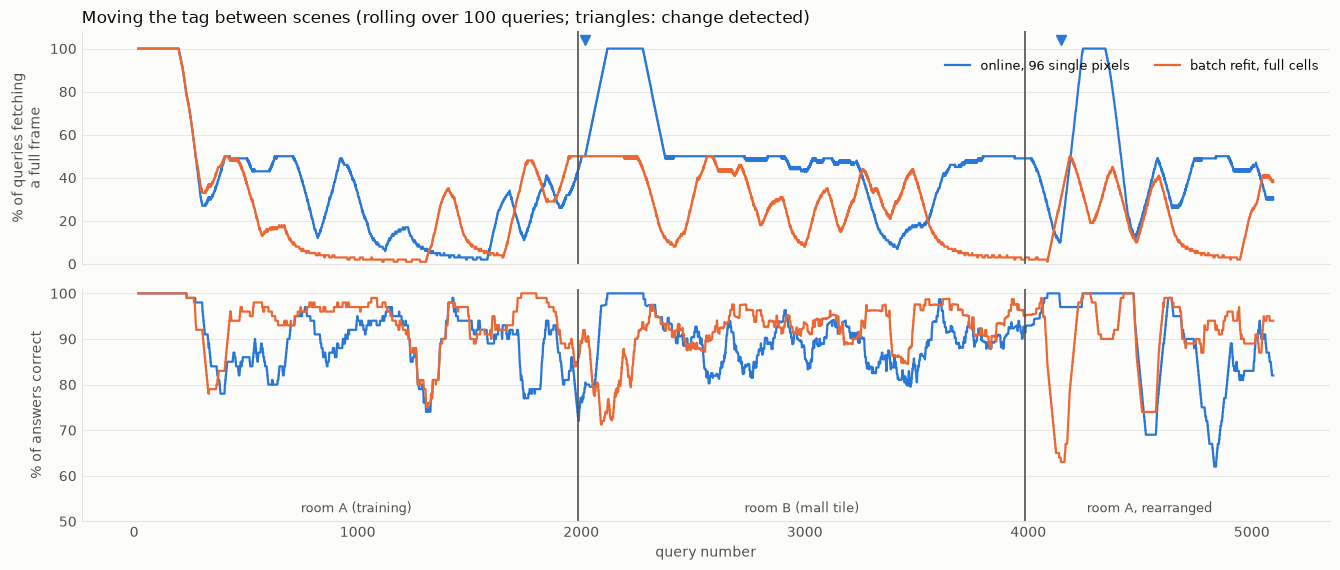

In [5]:
def timeline(names, labels, win=100):
    fig, axes = plt.subplots(2, 1, figsize=(13.5, 5.8), sharex=True)
    for name, label, color in zip(names, labels, [BLUE, ORANGE]):
        d = R[name]['df'].reset_index(drop=True)
        x = np.arange(len(d))
        roll = lambda v: pd.Series(v.astype(float)).rolling(win, min_periods=20).mean()
        axes[0].plot(x, roll(d.explored.values) * 100, color=color, lw=1.6, label=label)
        known = d.label.values >= 0
        ok = np.where(known, (d.answer.values == d.label.values).astype(float), np.nan)
        axes[1].plot(x, pd.Series(ok).rolling(win, min_periods=20).mean() * 100, color=color, lw=1.6, label=label)
        if 'changed' in d and d.changed.any():
            axes[0].plot(x[d.changed.values], np.full(d.changed.sum(), 104), 'v', color=color, ms=7)
    d['room'] = d.seq.map(room)
    starts = np.flatnonzero(d.room != d.room.shift())
    for ax in axes:
        for s in starts[1:]:
            ax.axvline(s, color=MUTED, lw=1.2)
        ax.grid(axis='y', color=GRID, lw=0.6); ax.set_axisbelow(True); ax.tick_params(length=0)
        for sp in ('top', 'right'):
            ax.spines[sp].set_visible(False)
    for s, e in zip(starts, list(starts[1:]) + [len(d)]):
        axes[1].text((s + e) / 2, 52, d.room[s], ha='center', fontsize=9, color=MUTED)
    axes[0].set_ylabel('% of queries fetching\na full frame'); axes[0].set_ylim(0, 108)
    axes[1].set_ylabel('% of answers correct'); axes[1].set_ylim(50, 101)
    axes[1].set_xlabel('query number')
    axes[0].set_title('Moving the tag between scenes (rolling over 100 queries; triangles: change detected)', fontsize=12)
    axes[0].legend(frameon=False, loc='upper right', fontsize=9, ncol=2, bbox_to_anchor=(1, 0.93))
    plt.tight_layout(); plt.show()

timeline(['switch_oracle_online_pixels', 'switch_oracle_batch_cells'],
         ['online, 96 single pixels', 'batch refit, full cells'])

**What the two learners do at a change.**
* **Online (blue).** At each change the full-frame rate goes to 100% within a few dozen queries (the triangles), stays there for the re-bootstrap, and the accuracy stays high throughout because the answers come from full frames. Afterwards the rate comes down only to about 50% in the Mall tile.
* **Batch (orange).** It keeps trusting the old code: accuracy drops to about 72% after the move and about 63% after the return. It recovers within a few hundred queries as its window fills with new frames, and then its check rate falls much further than the online learner's, to a few percent by the end of each stretch.
* The online learner also has dips of its own late in the rearranged room (down to about 62% near query 4,850) that it does not catch.

So the change detector buys accuracy during a transition at the price of a burst of full frames, and the batch refit buys a better code once enough new frames are in. The two are not exclusive: a detector could be added to a learner that settles better.


## Limits of this experiment

* **True labels on the `switch` stream.** With the detector as teacher the single-room results are four to nine points lower, and readaptation would be slower and less reliable than shown here.
* **The second "room" is not a room.** It is one tile of a crowded mall walkway at under 2 frames per second, where the label flips about 650 times in 2,000 frames. A high check rate there is partly the scene.
* **Readaptation time is mostly the bootstrap setting.** The server relearns from 200 labelled frames after a change. A shorter bootstrap would readapt faster with a worse first code; that trade-off is not measured.
* **Single runs, untuned.** Half-life, change threshold and bootstrap were set once. PIROPO is 30 minutes of staged scenarios.
* **Bytes and pixel counts, not energy.**

## What this suggests next

* **Cheaper checks** remain the largest lever, now for a second reason: readapting costs about 270 full frames.
* **A learner that settles.** Longer memory with the change detector as the reset, or a second, slower set of statistics, so the check rate keeps falling in a stable room as the batch refit's does.
* **Sweep the bootstrap length** to draw the readaptation-time against accuracy curve.
* **A detector teacher for every stream**, and a better one, so the whole experiment runs without labels.
* **Real multi-day data from two or three rooms**, which is what both claims finally need.
